# Part 1: KNN

# HW2: K-Nearest Neighbors Classification (25 points)

This notebook will guide you through:

- Preparing and exploring the MNIST dataset
- Computing simple features
- Implementing a KNN classifier from scratch
- Evaluating and analyzing your results


In [68]:
import numpy as np
import pandas as pd
import collections
import matplotlib.pyplot as plt
import warnings
# Ignore all user warnings (including NumPy/SciPy compatibility)
warnings.filterwarnings("ignore", category=UserWarning)
# Load Data
data = np.load("mnist_10k_trainval.npz")
x_all = data["x"]
y_all = data["y"]

print("Images shape:", x_all.shape)
print("Labels shape:", y_all.shape)
print("Label classes:", np.unique(y_all))

np.random.seed(0)

Images shape: (10000, 28, 28)
Labels shape: (10000,)
Label classes: [0 1 2 3 4 5 6 7 8 9]


---
**Note:** Decide your own train/validation/testing split here. You must clearly document it.


In [69]:
# TODO: Decide your split strategy here
# Example: use the first 1000 for training, next 1000 for validation
# You must document your choice.

## total of 10000 values

## First 4000 values are in training.
x_train = x_all[:4000]
y_train = y_all[:4000]

## Next 4000 values are in validation.
x_val = x_all[4000:8000]
y_val = y_all[4000:8000]

## last 2000 values are in testing.
x_left = x_all[8000:]
y_left = y_all[8000:]

## Ensuring they are the right size
print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Remaining samples:", x_left.shape)


Train shape: (4000, 28, 28)
Validation shape: (4000, 28, 28)
Remaining samples: (2000, 28, 28)


---
## Preprocessing the Data
Conduct any data manipulation you require to obtain the features dataframe (df_features in HW2_Starter).
You must showcase at least 3 features for each image. You can add additional features if you wish.



In [70]:
# TODO: Preprocess the data and create your features DataFrame
# You must compute at least 3 features per image and combine them with the labels.

## Flatten x_train from (28, 28) to (784,)
x_train_flat = x_train.reshape(len(x_train), -1)

## Normalize x_train_flat
x_train_norm = x_train_flat / 255.0

## Ensure normalize and flatten went as expected
# print("Shape after flattening:", x_train_norm.shape)
# print("Min/Max after normalization:", x_train_norm.min(), x_train_norm.max())

## Features Chosen:
## 1. Symmetrical Score (both horizontal and vertical)
## 2. Gap Score
## 3. Row Width of the

def find_gap(img):
    return sum(np.sum(img[i, :-1] != img[i, 1:]) for i in range(28))

def horizontal_symmetry_score(img):
    horizontal_top_half = img[:14, :]
    horizontal_bottom_half = img[14:, :]

    score = np.sum((horizontal_top_half - np.flipud(horizontal_bottom_half)))
    return score

def vertical_symmetry_score(img):
    vertical_top_half = img[:, :14]
    vertical_bottom_half = img[:, 14:]

    score = np.sum(vertical_top_half - np.fliplr(vertical_bottom_half))
    return score

def find_highest_row_length(img):
    col_sums = np.sum(img, axis=0)
    return np.max(col_sums)

x_horizontal_symmetry_score = np.array([horizontal_symmetry_score(img) for img in x_train])
x_vertical_symmetry_score = np.array([vertical_symmetry_score(img) for img in x_train])
x_highest_row_length_score = np.array([find_highest_row_length(img) for img in x_train])
x_gap_average = np.array([find_gap(img) for img in x_train])

x_val_horizontal_symmetry_score = np.array([horizontal_symmetry_score(img) for img in x_val])
x_val_vertical_symmetry_score = np.array([vertical_symmetry_score(img) for img in x_val])
x_val_highest_row_length_score = np.array([find_highest_row_length(img) for img in x_val])
x_val_gap_average = np.array([find_gap(img) for img in x_val])

df_features = pd.DataFrame({
    "gap_average": x_gap_average,
    "horizontal_symmetry_score": x_horizontal_symmetry_score,
    "vertical_symmetry_score": x_vertical_symmetry_score,
    "highest_row_length": x_highest_row_length_score
})

df_val_features = pd.DataFrame({
    "gap_average": x_val_gap_average,
    "horizontal_symmetry_score": x_val_horizontal_symmetry_score,
    "vertical_symmetry_score": x_val_vertical_symmetry_score,
    "highest_row_length": x_val_highest_row_length_score
})

df_normalized = (df_features - df_features.min()) / (df_features.max() - df_features.min())
df_val_normalized = (df_val_features - df_val_features.min()) / (df_val_features.max() - df_val_features.min())

# df_features.head(5)
# df_normalized.head(5)
df_val_normalized.head(5)
# print(df_test_normalized.dtypes)
# df_test_normalized.head(5)

,gap_average,horizontal_symmetry_score,vertical_symmetry_score,highest_row_length
0,0.484018,0.422672,0.577547,0.735800
1,0.543379,0.600891,0.539447,0.317661
2,0.607306,0.742696,0.592673,0.594033
3,0.214612,0.255077,0.224061,0.282100
4,0.433790,0.399794,0.320870,0.822196


---
## KNN Classifier

Implement your KNN classifier here.


In [71]:
# Example function stub, feel free to edit it in any shape or form outside of the function name
def knn_predictor(x_train, y_train, x_test, k):
    #Implement KNN here
    #Compute Distances, determine nearest neighbors, vote for class of sample

    predictions = []
    for test_point in x_test:
        ## get euclidian distance of all points in x_train to test point.
        distance = np.linalg.norm(x_train - test_point, axis=1)

        ## find k closest neighbors
        closest_neighbors = np.argsort(distance)[:k]

        ## nearest labels
        closest_labels = y_train[closest_neighbors]

        values, counts = np.unique(closest_labels, return_counts=True)
        max_counts = np.max(counts)
        tie_labels = values[counts == max_counts]
        classified_as = np.min(tie_labels)

        predictions.append(classified_as)
    return np.array(predictions)


---
## Evaluate Accuracy for Different k Values

In this step, you will:

- Choose a list of values for $k$ (for example: 1, 3, 5, 7, 9). Choose at least 5 values to test k for, you can explore further values to explore trends or to determine a best value.
- Use your `knn_predictor` function to make predictions on the validation set for each $k$.
- Calculate the accuracy for each $k$ by comparing predictions to the true labels.
- Print out the results so you can see which $k$ performs best.


**Note:** You can use either odd or even values for $k$. If you encounter ties in majority voting, break them consistently (for example, by choosing the smallest label).


In [72]:
# TODO: Evaluate accuracy for different k values

k_values = [1, 2, 3, 4, 5, 10, 15, 20, 25, 30, 38, 39, 40, 41, 42, 45, 60, 75, 90, 37, 36, 35, 34, 33, 32, 31]
accuracies = {} # Store your accuracies in a dictionary so you can easily compare them later.

def find_accuracy(predictions, true_labels):
    accurate_array = np.array(predictions == true_labels)
    
    accurate_count = 0
    for bool in accurate_array:
        if bool == True:
            accurate_count+=1
    
    return accurate_count / np.size(accurate_array)


for k in k_values:
    preds = knn_predictor(df_normalized.values, y_train, df_val_normalized.values, k)
    accuracy = find_accuracy(preds, y_val)
    accuracies[k] = accuracy
    print(f"k = {k}, accuracy = {accuracy:.4f}")


k = 1, accuracy = 0.2530
k = 2, accuracy = 0.2530
k = 3, accuracy = 0.2700
k = 4, accuracy = 0.2825
k = 5, accuracy = 0.2905
k = 10, accuracy = 0.3088
k = 15, accuracy = 0.3227
k = 20, accuracy = 0.3365
k = 25, accuracy = 0.3412
k = 30, accuracy = 0.3445
k = 38, accuracy = 0.3458
k = 39, accuracy = 0.3435
k = 40, accuracy = 0.3445
k = 41, accuracy = 0.3455
k = 42, accuracy = 0.3440
k = 45, accuracy = 0.3420
k = 60, accuracy = 0.3435
k = 75, accuracy = 0.3455
k = 90, accuracy = 0.3453
k = 37, accuracy = 0.3453
k = 36, accuracy = 0.3435
k = 35, accuracy = 0.3435
k = 34, accuracy = 0.3420
k = 33, accuracy = 0.3450
k = 32, accuracy = 0.3422
k = 31, accuracy = 0.3448


## Evaluating on the Test Set

In this step, you will use your KNN classifier with the best $k$ value to predict labels for the test set and evaluate its performance.

Since the test set includes labels, you can:

- Calculate the accuracy on the test set


In [73]:
#Testing the KNN Model

In [74]:
# TODO: Evaluate your KNN classifier on the test set

# Load test data
test_data = np.load("mnist_1k_test.npz")
x_test = test_data["x"]
y_test = test_data["y"]

# Do any preprocessing required
x_test_horizontal_symmetry_score = np.array([horizontal_symmetry_score(img) for img in x_test])
x_test_vertical_symmetry_score = np.array([vertical_symmetry_score(img) for img in x_test])
x_test_highest_row_length_score = np.array([find_highest_row_length(img) for img in x_test])
x_test_gap_average = np.array([find_gap(img) for img in x_test])

df_test_features = pd.DataFrame({
    "gap_average": x_test_gap_average,
    "horizontal_symmetry_score": x_test_horizontal_symmetry_score,
    "vertical_symmetry_score": x_test_vertical_symmetry_score,
    "highest_row_length": x_test_highest_row_length_score
})

df_test_normalized = (df_test_features - df_test_features.min()) / (df_test_features.max() - df_test_features.min())

# Predict using your best k from the validation set.
prediction = knn_predictor(df_normalized.values, y_train, df_test_normalized.values, 20)

# Calculate accuracy by comparing your predicted labels vs the actual ones in y_test
test_accuracy = find_accuracy(prediction, y_test)
print(f"Test set accuracy: {test_accuracy:.4f}")

Test set accuracy: 0.3740


## Reflection and Analysis

Answer the following questions. You may include text, plots, and code as needed.

---

### 1. Effect of k on Validation Accuracy

- How did changing \(k\) affect your validation accuracy?
- Create a plot showing accuracy for each \(k\).

*Add your plot and brief explanation below:*


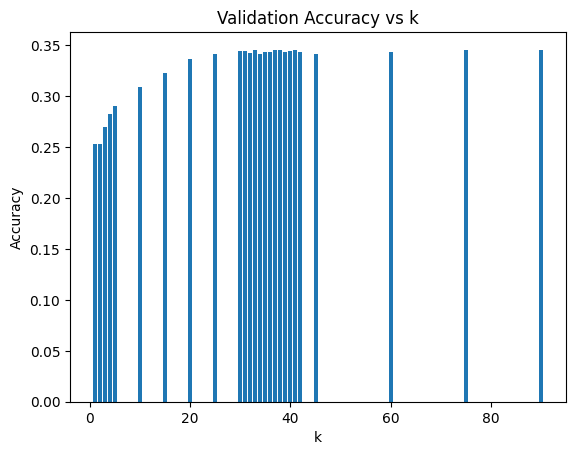

In [75]:
# Example: plotting accuracy vs k 
import matplotlib.pyplot as plt

plt.bar(k_values, list(accuracies.values()))
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy vs k")
plt.show()


- Why do you think this the plot looks like it does and how does changing $k$ affect your accuracy on the validation set?




The plot looks like a logarithmic curve because as our k-value gets bigger, the program sort of hits a plateau and smooths out due to the excess amount of data that we have from KNN. We underfit the program and it becomes too simple generalizing things that maybe should've stood out more. As our k-value gets lower, we overfit and the model may be too complex and might ignore outliers or any noise in the data set. A really low k usually gives a low score, a really large k is smooth out at around 0.345, with 38 currently being the best at 0.3458.

## 2. Confusion Matrix Analysis

#### What is a Confusion Matrix?

A **confusion matrix** is a table used to evaluate the performance of a classification model. 

- Each **row** represents the actual class.
- Each **column** represents the predicted class.
- The diagonal cells show the number of correct predictions for each class.
- The off-diagonal cells show where the model made mistakes (e.g., predicting a 5 when the true label was 3).

This visualization helps you see **which digits are most often confused** and where your classifier might need improvement.


- Which digit classes were most frequently confused for your KNN classifier?
- Create and display your confusion matrix to help you observe these patterns in both your validation set and test set.

*Insert your confusion matrix visualization either after the one provided for you or edit the existing code.*


My program was easily able to identify numbers such as 0, 1, 7, 8, and 9 in the test data, but when it came to numbers like 2, which were a little harder to guess due to the nature of my features, failed horribly.Generally across the diagonal, the predicted value vs the true value is about 25% correct besides 2 and 3, which seem to be the hardest numbers for my program to guess correctly.

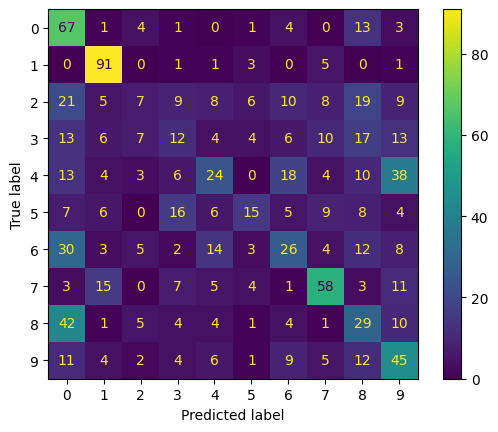

In [76]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Dummy true labels and predictions
y_ground_truth = y_test
y_predictions = prediction

# Compute confusion matrix
cm_example = confusion_matrix(y_ground_truth, y_predictions)

# Plot Confusion Matrix
cm_plot = ConfusionMatrixDisplay(confusion_matrix=cm_example)
cm_plot.plot()

----
## 3. Runtime Performance

- How long did it take to run predictions for your validation set?
- What about your performance on the test set?
- What impact does the value of $k$ have on this?
- Does the best value of $k$ for your validation set hold true for the test set? Why or Why not?

*You can measure time using the following example code:*
 start_time = time.time()
 preds = knn_predictor(...)
 end_time = time.time()

In [77]:
import time
start_time = time.time()
pred = knn_predictor(df_normalized.values, y_train, df_val_normalized.values, 38)
end_time = time.time()

print("Validation Set: ", end_time - start_time)

start_time = time.time()
pred = knn_predictor(df_normalized.values, y_train, df_test_normalized.values, 38)
end_time = time.time()

print("Test Set: ", end_time - start_time)

Validation Set:  0.8880033493041992
Test Set:  0.34563159942626953


My knn_predictor function ran for my validation set in about 0.35 seconds. On the test set, it took about 0.09 seconds. The k-value generally has no impact on the run time as we are just getting the k-nearest neighbors from our point which can be done through numpy and a list pretty quickly. The best k value for my validation set does not necessarily hold for my test set as there is a different amount of data (4000 in validation, 1000 in test set) thus the test set may reach overfitting or underfitting on the k-value much sooner than the validation set. I ran a few tests and a k-value of around 20 is way higher than the score I got for the validation k-value 38.

---
## Additional Analysis
If you want to conduct any additional exploration, you can report it here.

---
Use additional cells if you need more space or want to add extra visualizations.

---
# Part 2: K-Means Clustering (25 points)

### Cheesecake Consumers Dilemma

In this assignment, you will analyze a dataset of customers visiting a cheesecake shop.

Your goals are to:

- Explore the dataset and determine which features you believe are meaningful for clustering
- Experiment with different values of $k$
- Implement K-Means clustering from scratch
- Interpret your results

**Note:** You may use NumPy, Pandas, and Matplotlib. You may not use scikit-learn's `KMeans` for your own implementation. Any provided code can be modified, it is just there to guide you or offer additional insight to the directions.


### Load and Inspect the Data

Load the dataset and explore its structure.


In [1]:
import pandas as pd
# Load the CSV file
df = pd.read_csv("CheesecakeConsumers.csv")

## df Contains:
##
## CustomerNo: starts at 1
## Gender: male or female
## Age of the customer
## Spending Power of the customer
## Consumer score
##
## 200 rows by 5 columns

## Possible Centroids
##  1. Centroid could be consumer score, within a range of maybe 10? (score range is 1 - 99)
##  2. Centroid could be spending power, within a range of 15 - 20? larger score range to look from. (score range 15 - 137)
##  3. Centroid could be age, maybe not the best judge of a customer? (range from 18 - 70)
##  4. or, we can normalize everything and take that score and find centroids
## Gender and age don't really hold any power as centrioids but could be useful for classification.

df_cheesecake = pd.DataFrame({
    "age": df["Age"],
    "spending_power": df["Spending Power"],
    "consumer_score": df["Consumer Score"]
})

df_cheesecake_normalized = ((df_cheesecake - df_cheesecake.min()) / (df_cheesecake.max() - df_cheesecake.min()))
df_cheesecake_normalized.head(10)

,age,spending_power,consumer_score
0,0.019231,0.000000,0.387755
1,0.057692,0.000000,0.816327
2,0.038462,0.008197,0.051020
3,0.096154,0.008197,0.775510
4,0.250000,0.016393,0.397959
5,0.076923,0.016393,0.765306
6,0.326923,0.024590,0.051020
7,0.096154,0.024590,0.948980
8,0.884615,0.032787,0.020408
9,0.230769,0.032787,0.724490


## K-Means Implementation

Implement K-Means clustering from scratch below.



In [ ]:
# TODO: Implement your K-Means algorithm

# Example structure:
def kmeans(features, k, max_iters=20): #Remember we don't want an infinite loop so we'll end the algorithm after max_iters
    n_samples, n_features = features.shape
    labels = []

    np.random.seed(0)
    centroid_labels = np.random.choice(n_samples, k, replace=False)
    centroids = features[centroid_labels]

    for i in range(max_iters):
        distances = np.linalg.norm(features[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)

        centroids = np.array([features[labels == i].mean(axis=0) for i in range(k)])

    return labels, centroids

In [80]:
### If you wish to test your implementation prior to interacting with real data 
### Feel free to use the following code stub to see if you can cluster the following dummy data

# X_test = np.vstack([ np.random.normal(loc=0.0, scale=0.5, size=(10, 2)),
#     np.random.normal(loc=5.0, scale=0.5, size=(10, 2))])

# plt.scatter(X_test[:,0], X_test[:,1], s=50)
# plt.title("Dummy Data 2 Clusters")
# plt.show()


## Run Your K-Means

Run your implementation with your chosen k on the cheesecake consumer data, feel free to try multiple runs and determine what k best clusters this data.

Defend your best k value after deciding on one, you should use visual aids like scatterplots to make your point.

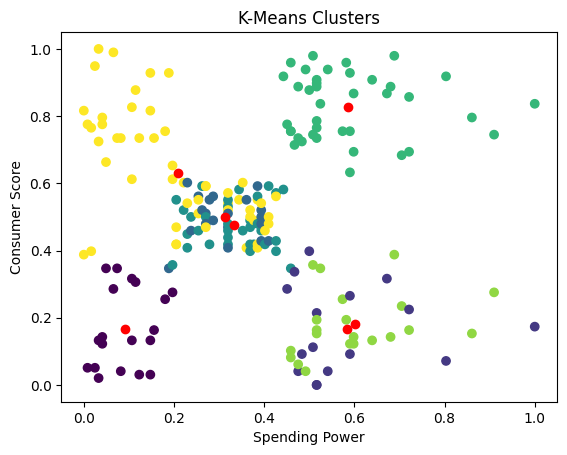

In [280]:
#  Run your K-Means
labels, centroids = kmeans(df_cheesecake_normalized.values, k=7, max_iters=20)

## Feel free to use some of the following stub to assist you in plotting it
plt.scatter(df_cheesecake_normalized["spending_power"], df_cheesecake_normalized["consumer_score"], c=labels, cmap="viridis")
## Also plot your centroids on this plot for visual clarity
plt.scatter(centroids[:, 1], centroids[:, 2], c="red")
plt.xlabel("Spending Power")
plt.ylabel("Consumer Score")
plt.title("K-Means Clusters")
plt.show()

## Testing New Data

Below are 5 new customers alongside their data attributes:

| ID | Age | Gender | Spending Power| Consumer Score (1–100) |
|----|-----|--------|---------------|------------------------|
| 1  | 24  | Female | 25            | 85                     |
| 2  | 52  | Male   | 80            | 20                     |
| 3  | 35  | Female | 55            | 60                     |
| 4  | 42  | Male   | 45            | 30                     |
| 5  | 29  | Female | 90            | 75                     |

**Tasks:**
1. Standardize these 5 samples the same way you processed your original data.
2. Assign each sample to the closest cluster centroid (from your implementation).
3. Plot these points on top of your clustered data, using distinct markers or colors.


In [84]:
df_test_cheesecake = pd.DataFrame({
    "age": [24, 52, 35, 42, 29],
    "spending_power": [25, 80, 55, 45, 90],
    "consumer_score": [85, 20, 60, 30, 75]
})

df_test_cheesecake_norm = ((df_test_cheesecake - df_test_cheesecake.min()) / (df_test_cheesecake.max() - df_test_cheesecake.min()))
df_test_cheesecake_norm.head()

,age,spending_power,consumer_score
0,0.000000,0.000000,1.000000
1,1.000000,0.846154,0.000000
2,0.392857,0.461538,0.615385
3,0.642857,0.307692,0.153846
4,0.178571,1.000000,0.846154


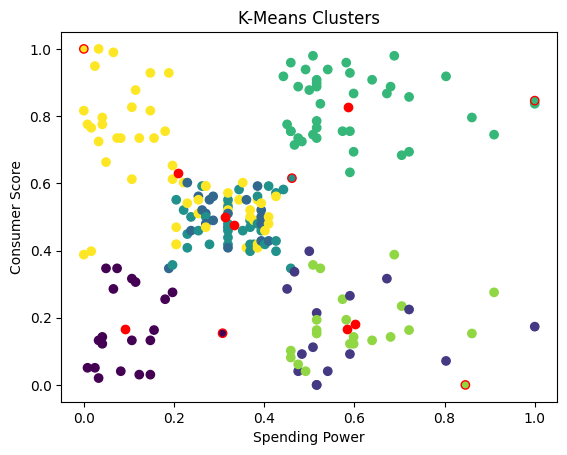

In [294]:
test_cheesecake_labels = []
for point in df_test_cheesecake_norm.values:
    distance = np.linalg.norm(centroids - point, axis=1)
    label = np.argmin(distance)
    test_cheesecake_labels.append(label)

plt.scatter(df_cheesecake_normalized["spending_power"], df_cheesecake_normalized["consumer_score"], c=labels, cmap="viridis")
plt.scatter(centroids[:, 1], centroids[:, 2], c="red")
## test points ontop of existing points
plt.scatter(df_test_cheesecake_norm["spending_power"], df_test_cheesecake_norm["consumer_score"], c=test_cheesecake_labels, edgecolor="red", cmap="viridis")

plt.xlabel("Spending Power")
plt.ylabel("Consumer Score")
plt.title("K-Means Clusters")
plt.show()
    

I chose a k-value of 7 after testing as a k-value higher than 7 introduces a lot of smaller clusters (that have like 5-10 points) that would be meaningless and just overclassify the data. Seeing as how the 5 test points all have their own distinct clusters and no overlaps, I think 7 is a solid choice since theres several distinct clusters although theres 2-3 clusters that overlap in the middle-right.

## Analysis and Reflection

Answer the following questions:

1. What patterns or groups do you notice in your clusters?
2. Does the value of max iterations pay a large role in your algorithm? Try various values to showcase your answer.
3. Why might K-Means struggle to perfectly separate customers?
4. If you had more features, what other data would you collect?



I noticed that my clusters are somewhat distinct but for some reason theres a spot where there overlaps atleast 3 or 4 clusters with my k-value of 7. The most distinct clusters are the ones in the corners.

The value of max iterations does not play an immense role in my algorithm, I tested with an extremely large value of 300, and nothing really changed, but I went down to 1, 2, 3, 4, 5 and by the time I tried 4, the changes didn't really appear, so it doesn't play a large part in my algorithm.

K-Means can struggle to perfectly seperate customers due to lack of data, poor data, or a poor k-value. There are several reasons to it since the features I chose to map (consumer score, spending power) have generally the same range of data, so the clusters may overlap a lot.

If I had more features, I would collect data like frequency of shopping, amount of items bought, amount spent daily/weekly/total, more stuff that distinguishes customers.

## Comparison with scikit-learn KMeans

To review your own implementation we will:

- Use scikit-learn's KMeans to cluster the original cheesecake consumers data (Not the testing samples).
- Compare scikit-learn's centroids and labels to your own implementation.
- Reflect on similarities or differences.

**Note:** This is to help you evaluate your implementation, it does not affect your grade if results are not identical.


In [300]:
# TODO: Fit scikit-learn KMeans for comparison

from sklearn.cluster import KMeans

# Fit KMeans
kmeans_sklearn = KMeans(n_clusters=7, random_state=0)
kmeans_sklearn.fit(df_cheesecake_normalized)

# Get labels and centroids
sklearn_labels = kmeans_sklearn.labels_
sklearn_clusters = kmeans_sklearn.cluster_centers_


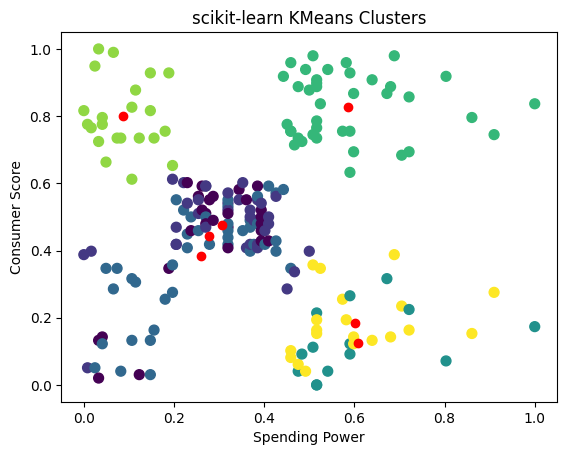

In [303]:
# TODO: Plot scikit-learn clusters

import matplotlib.pyplot as plt

plt.scatter(df_cheesecake_normalized["spending_power"], df_cheesecake_normalized['consumer_score'], c=sklearn_labels, cmap='viridis', s=50)
plt.scatter(sklearn_clusters[:, 1], sklearn_clusters[:, 2], c="red")
plt.xlabel("Spending Power")
plt.ylabel("Consumer Score")
plt.title("scikit-learn KMeans Clusters")
plt.show()


## Reflection on Comparison

Answer the following:

- How similar are the clusters to your implementation?
- Did scikit-learn converge to the same or different centroids?
*Write your reflection below.*


The clusters are generally pretty similar to my implementation but they had different clusters near the middle-left and bottom-left areas. They had some similar centroids but in the same area their centroids were different and converged to different points.